# 03 · Demand forecast and the winter 2026/27 offer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/mobility/bus-network-demand-planning/notebooks/03_forecast_and_winter_plan.ipynb)

Bookings are not demand. When a bus sells out, the people who wanted a seat and did not get one
leave no trace in the data. A forecast trained on raw bookings would therefore plan too few seats
exactly where more are needed.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "mobility/bus-network-demand-planning"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "bus_network").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: bus-network-demand-planning


In [2]:
from bus_network import config as C, data, validation as V, analysis as A, planning as P, reporting as R, db

if not any(Path("data").glob("*.csv*")):
    data.save(data.generate(), Path("data"))
tables = data.load(Path("data"))
LAST_12M = ("2025-10-01", "2026-09-30")
print({name: len(df) for name, df in tables.items()})
trips = V.clean_trips(tables)

{'bookings': 80380, 'line_stops': 73, 'od_monthly': 6138, 'operations': 80180, 'partners': 9, 'stops': 33, 'timetable': 80, 'truth_demand': 80320}


## Forecast

The model is a log-linear regression per departure with month, weekday, holiday and a trend per
line. Sold-out trips are treated as censored: their demand is set to at least the bookings and
re-estimated from the model, repeated until it settles.

The backtest trains on data before 14 December 2025 and forecasts the 2025/26 winter timetable. The
synthetic data keeps the true demand, so the forecast can be scored against what people actually
wanted, not only against what they managed to book.

In [3]:
bt, weekly = P.backtest(trips, tables["truth_demand"], tables["timetable"])
pd.Series(bt).round(3)

model_wape_vs_true_demand           0.045
naive_wape_vs_true_demand           0.158
bookings_understate_demand_pct      0.041
model_bias_pct                     -0.004
weeks                             747.000
dtype: float64

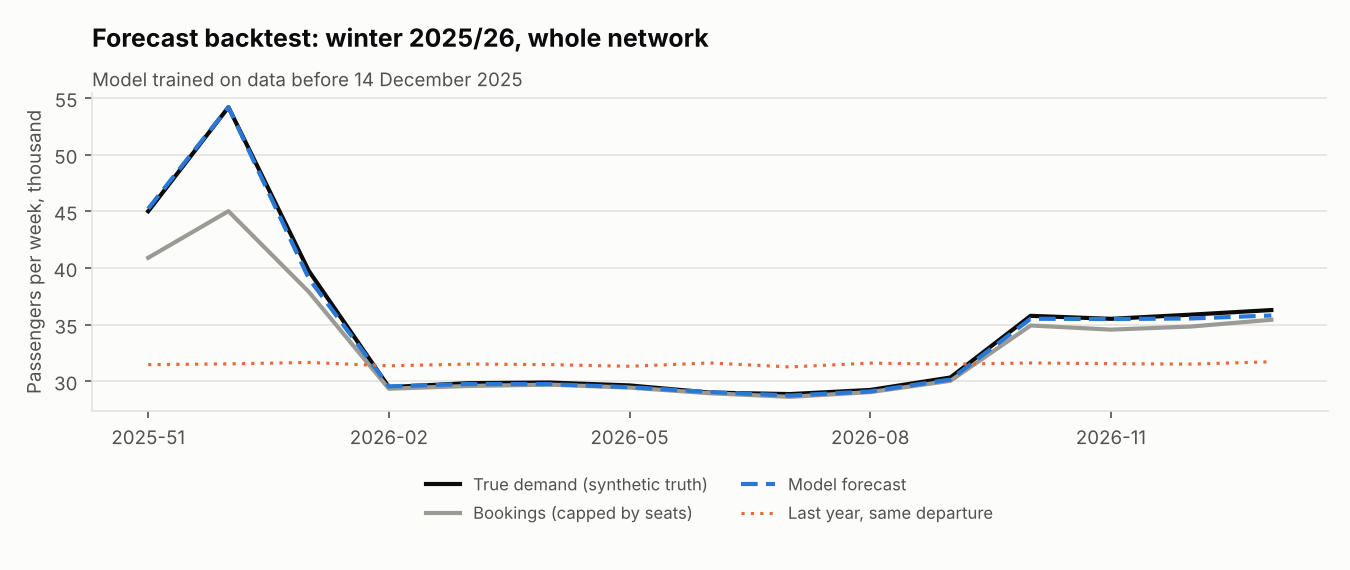

In [4]:
R.plot_backtest(weekly, Path("outputs/figures/forecast_backtest.png"))
display(Image("outputs/figures/forecast_backtest.png"))

## Offer options

For every line and direction there are 16 options: 1 to 8 departures a day, single or double-decker.
Each option is simulated 200 times with demand noise, which gives passengers carried, sold-out share,
revenue, bus cost and bus-hours for the whole winter season. More departures also attract some
extra demand (elasticity 0.35).

In [5]:
model = P.DemandModel().fit(trips)
opts = P.options(model, trips, tables["timetable"], C.PLAN_SEASON)
opts[opts["line"] == "L016"].query("direction == 'A' and departures <= 3")[
    ["departures", "bus", "served_pax", "sold_out_share", "contribution_eur", "bus_hours", "is_current"]].round(2)

,departures,bus,served_pax,sold_out_share,contribution_eur,bus_hours,is_current
192,1,single,4446.29,0.38,108850.98,946.8,True
193,1,double,5026.23,0.07,115698.32,946.8,False
194,2,single,6379.19,0.08,96442.08,1893.6,False
195,2,double,6553.80,0.00,62601.12,1893.6,False
196,3,single,7511.60,0.02,45413.48,2840.4,False
197,3,double,7564.13,0.00,-15450.11,2840.4,False


## Choosing the plan

A mixed-integer program picks one option per line and direction. It maximises contribution with
these rules: total bus-hours at most 3% above today, at least as many passengers as today, both
directions of a line get the same offer, partners cannot run more double-deckers than they own,
and no new option may sell out on more than a quarter of departures.

In [6]:
opts = P.optimise(opts, tables["partners"])
plan = P.plan_table(opts)
plan[(plan["direction"] == "A") & (plan["change"] == "change")][
    ["line", "current", "proposed", "sold_out_now", "sold_out_plan", "contribution_delta"]]

,line,current,proposed,sold_out_now,sold_out_plan,contribution_delta
0,L010,3 x double,2 x double,0.080,0.219,34635.0
4,L012,3 x single,2 x double,0.221,0.099,11200.0
6,L013,1 x double,2 x double,0.330,0.060,-11340.0
8,L014,3 x single,2 x double,0.280,0.132,23879.0
10,L015,3 x single,2 x double,0.282,0.133,17454.0
12,L016,1 x single,1 x double,0.380,0.066,6847.0
16,L020,3 x double,5 x single,0.136,0.233,-34323.0
32,L040,4 x double,3 x double,0.091,0.189,35427.0
36,L042,2 x single,2 x double,0.407,0.077,4499.0
38,L043,1 x single,1 x double,0.205,0.023,-5460.0


In [7]:
tot = plan[["served_now", "served_plan", "contribution_now", "contribution_plan", "bus_hours_now", "bus_hours_plan"]].sum()
print(f"Passengers  {tot.served_now:,.0f} -> {tot.served_plan:,.0f}")
print(f"Contribution {tot.contribution_now:,.0f} -> {tot.contribution_plan:,.0f} EUR ({tot.contribution_plan / tot.contribution_now - 1:+.1%})")
print(f"Bus-hours   {tot.bus_hours_now:,.0f} -> {tot.bus_hours_plan:,.0f} ({tot.bus_hours_plan / tot.bus_hours_now - 1:+.1%})")
print(f"Average sold-out share {plan.sold_out_now.mean():.1%} -> {plan.sold_out_plan.mean():.1%}")

Passengers  539,132 -> 539,541
Contribution 3,295,541 -> 3,460,680 EUR (+5.0%)
Bus-hours   55,080 -> 52,000 (-5.6%)
Average sold-out share 17.2% -> 11.8%


Most changes swap three single-deckers for two double-deckers: the same seats with fewer buses and
drivers. L016 Berlin to Warsaw moves to a double-decker. L020 goes the other way and gets more,
smaller departures, because the plan has to carry at least as many passengers as today and L020 is
the cheapest place to add capacity. That is a choice for the planner to confirm, not an automatic
decision.

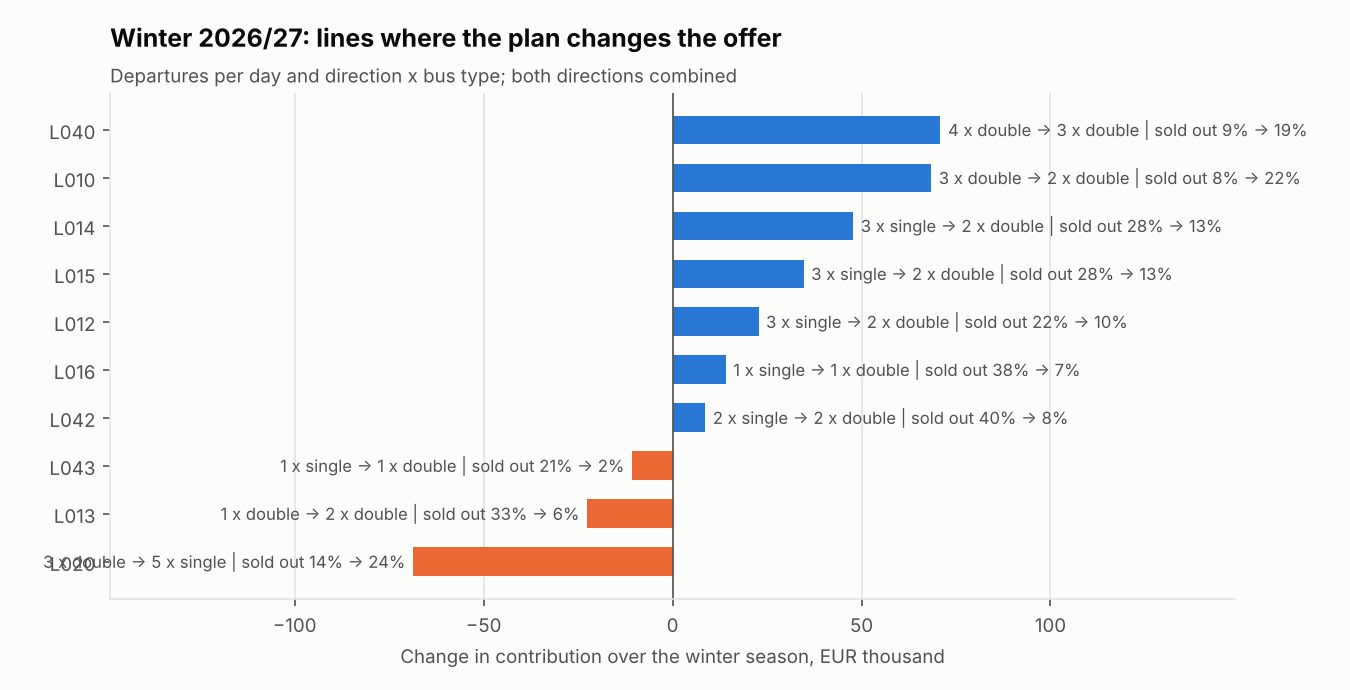

In [8]:
R.plot_plan(plan, Path("outputs/figures/winter_plan.png"))
display(Image("outputs/figures/winter_plan.png"))

## The Excel report

One workbook for the planning team: the issue log with an open-issue counter, line KPIs with formulas
for load factor and contribution, the winter plan, demand gaps and monthly passengers per line.

In [9]:
from openpyxl import load_workbook
xlsx = R.write_excel(Path("outputs/network_planning_report.xlsx"), issues=V.issue_log(V.run_all(tables)),
                     kpis=A.line_kpis(trips, LAST_12M), plan=plan,
                     gaps=A.demand_gaps(A.fit_gravity(tables["od_monthly"], LAST_12M), A.network_graph(trips, LAST_12M)),
                     monthly=trips.groupby(["line", "month"])["pax"].sum().reset_index())
wb = load_workbook(xlsx)
print("Sheets:", wb.sheetnames)
print("Example formulas:", wb["Line KPIs"]["I2"].value, "|", wb["Winter plan"]["L2"].value, "|", wb["Issue log"]["C11"].value)

Sheets: ['Read me', 'Issue log', 'Line KPIs', 'Winter plan', 'Demand gaps', 'Monthly passengers']
Example formulas: =E2/F2 | =K2-J2 | =COUNTIFS(C2:C9,"FAIL",H2:H9,"<>x")
